In [109]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

In [101]:
proposal_number = 101927227  # noqa
run = 100  # noqa

In [102]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='epix_6/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

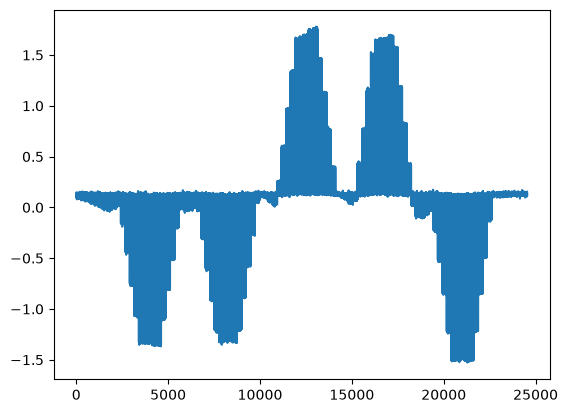

In [103]:
plt.plot(h5[h5dict.measured_voltage][...])

In [104]:
mean_im = np.mean(h5[h5dict.stack][::100, ...], axis=0)

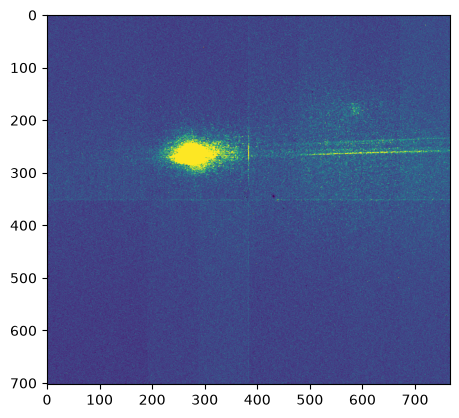

In [105]:
plt.imshow(mean_im, vmin=0, vmax=0.3)

In [120]:
voltage_high = (np.absolute(h5[h5dict.measured_voltage][...]) > 1.0)
laser_on = h5[h5dict.laser_on][...].astype(bool)
n_on = np.count_nonzero(voltage_high)
n_off = np.count_nonzero((~voltage_high) & (~laser_on))
laser_on

array([False,  True, False, ...,  True, False,  True], shape=(24543,))

In [122]:
stack = h5[h5dict.stack]
mean_on = np.zeros(stack.shape[1:])
mean_off = np.zeros(stack.shape[1:])
for i in tqdm(list(range(stack.shape[0]))):
    if laser_on[i] and voltage_high[i]:
        mean_on += stack[i, ...] / n_on
    elif not laser_on[i] and not voltage_high[i]:
        mean_off += stack[i, ...] / n_off

100%|██████████| 24543/24543 [00:20<00:00, 1193.27it/s]


/lscratch/bfichera/tmp/ipykernel_3010723/1170587902.py:2: RuntimeWarning: invalid value encountered in divide
  axs[0].imshow(mean_on / mean_off - 1.0, vmin=-0.1, vmax=0.1, cmap='RdBu_r')


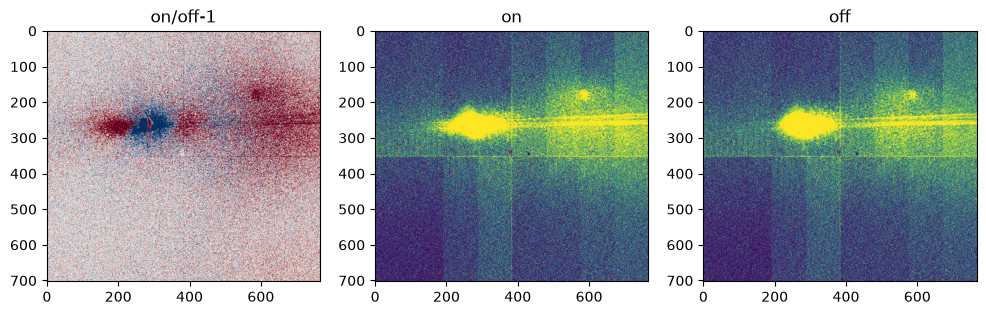

In [132]:
fig, axs = plt.subplots(1, 3, figsize=(12, 12))
axs[0].imshow(mean_on / mean_off - 1.0, vmin=-0.1, vmax=0.1, cmap='RdBu_r')
axs[1].imshow(mean_on, vmin=0.05, vmax=0.1)
axs[2].imshow(mean_off, vmin=0.05, vmax=0.1)
axs[0].set_title('on/off-1')
axs[1].set_title('on')
axs[2].set_title('off')
plt.show()

In [85]:
diff = (
    np.mean(h5[h5dict.stack][4000:4500:2, ...], axis=0)
    / np.mean(h5[h5dict.stack][4001:4501:2, ...], axis=0)
    - 1.0
)


/lscratch/bfichera/tmp/ipykernel_3010723/4162986984.py:2: RuntimeWarning: invalid value encountered in divide
  np.mean(h5[h5dict.stack][4000:4500:2, ...], axis=0)


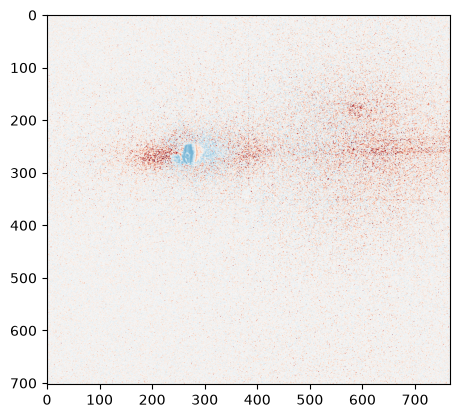

In [89]:
plt.imshow(diff, vmin=-2.0, vmax=2.0, cmap='RdBu_r')

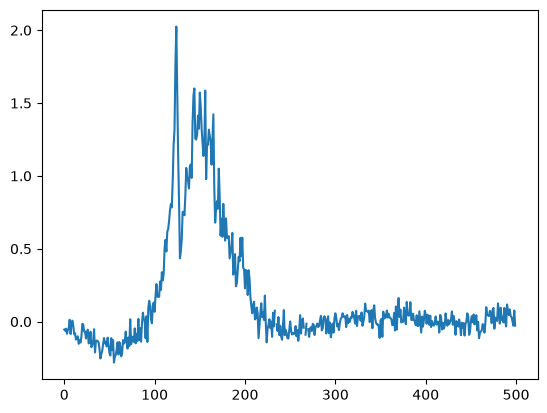

In [60]:
plt.plot(np.mean(diff[150:200, ...], axis=0))

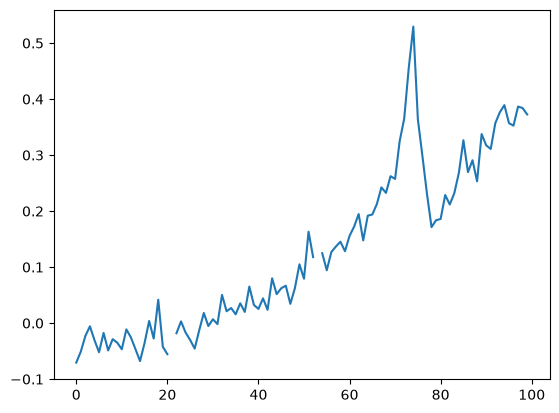

In [59]:
plt.plot(np.mean(diff[..., 50:150], axis=0))

In [ ]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

In [ ]:
on_meta = metadata[metadata['laser_on']]
off_meta = metadata[~metadata['laser_on']]
fig, axs = plt.subplots(1, 2)
for ax in axs:
    ax.plot(on_meta['measured_voltage'], label='on', color='red')
    ax.plot(off_meta['measured_voltage'], label='off', color='blue')
    ax.set_xlabel('frame')
    ax.set_ylabel('measured_voltage')
axs[1].set_ylim(bottom=0.0, top=0.3)
plt.legend()
plt.show()

In [ ]:
rois = [
    (slice(160, 170), slice(168, 178)) # whole ROI
]

In [ ]:
print(metadata['measured_voltage'][4004])
plt.imshow(h5[h5dict.stack][4004, ...])

In [ ]:
xcs.plot_detector_image(h5, h5dict, samplerate=100, vmin=0, vmax=0.3)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

In [ ]:
xcs.plot_i0_vs_time(metadata, valid).show()

In [ ]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

In [ ]:
xcs.plot_intensity_vs_time(metadata, valid).show()

In [ ]:
delays = h5[h5dict.delay][...]
diff = np.diff(delays)
u_diffs, counts = np.unique(diff, return_counts=True)
typical_dt = u_diffs[u_diffs > 0][np.argmax(counts[u_diffs > 0])]
print(f'{typical_dt=:0.2f}')

In [ ]:

fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'on/off (roi {j})' if i == 0 else None
        ax.plot(trxrd.index, trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], color=color, linestyle='-', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

In [ ]:


def normalize(a):
    return a / np.amax(a)


fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'off (roi {j})' if j == i else None
        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

In [ ]:

off_filter = valid[~metadata['laser_on']]
off_metadata = metadata[~metadata['laser_on']]
for j, (roi, color) in enumerate(zip(rois, roi_colors)):
    off_st_corr, off_st_twotime = xcs.calc_static_correlation(h5, h5dict, off_metadata, off_filter, roi=roi, denominator_type='nanmean', ret_twotime=True)
    fig, axs = plt.subplots(1, 2)
    axs[0].semilogx(off_st_corr, label=f'roi {j}', color=color)
    axs[1].imshow(off_st_twotime, origin='lower')
    axs[0].set_xlabel(r'$\Delta$ frame#')
    axs[0].set_ylabel(r'$g_2(frame_1, frame_2) - 1$')
    axs[1].set_xlabel(r'frame$_1$')
    axs[1].set_ylabel(r'frame$_2$')
    fig.suptitle(f'Run {run:04d}, roi {j}, off correlation')
    fig.tight_layout()
    fig.show()

In [ ]:
# TODO
# Try other reversibility conditions?
comparable_labtime_frames = 500
per_frame_time = (metadata['event_time'].max() - metadata['event_time'].min())/len(metadata)
labtime_bin_interval = comparable_labtime_frames * per_frame_time
for j, (roi, color) in enumerate(zip(rois, roi_colors)):
    diffcorr = xcs.differential_correlation('strong',
                                            h5,
                                            h5dict,
                                            metadata,
                                            valid,
                                            typical_dt,
                                            labtime_bin_interval,
                                            roi=roi,
                                            denominator_type='nanmean')
    fig, ax = plt.subplots()
    ax.plot(diffcorr.index, diffcorr)
    ax.set_xlabel('delay')
    ax.set_ylabel('diffcorr')
    fig.suptitle(f'Run {run:04d}, roi {j}, diffcorr')
    fig.tight_layout()
    fig.show()